# Point-in-time backtest of the risk score

For each inspection round (each vessel's 2nd, 3rd and 4th inspection), every vessel is scored using only the records dated **before** that vessel's inspection, then the fleet is ranked. The question is where the vessels that went on to have a bad outcome (Major Deficiencies or Detention) ranked.

Only the inspection and deficiency components are used. Maintenance, crew, audit and failure records in the sample data are dated after the inspections, so they can't be placed in time. A deficiency counts as open at the cut-off if it was closed on or after that date.

The same code (`app/backtest.py`) serves `GET /api/backtest`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

API_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(API_DIR))

from app.backtest import run_backtest
from app.scoring import load_rules
from tests.sample_data import load_sample

rules = load_rules(API_DIR / "rules.yaml")
result = run_backtest(load_sample(), rules, top_n=2)

## Where the bad outcomes ranked

In [2]:
pd.DataFrame(result["bad_outcomes"])[
    ["round", "vessel_id", "inspection_id", "inspection_date", "outcome", "score", "rank", "tied_with"]
]

,round,vessel_id,inspection_id,inspection_date,outcome,score,rank,tied_with
0,3,V001,INS0003,2025-01-11,Major Deficiencies,26.4,1,0
1,4,V001,INS0004,2025-06-29,Detained,50.0,1,0
2,4,V004,INS0016,2025-05-26,Detained,21.5,3,1


## Recall and precision by shortlist size

Flagging every vessel ranked N or better in each round. Vessels tied at the cut-off are all flagged.

In [3]:
curve = pd.DataFrame(result["recall_curve"]).set_index("top_n")
per_round = pd.DataFrame(
    [{"round": rd["round"], "top_n": n, "flags": sum(r["rank"] <= n for r in rd["ranking"])}
     for rd in result["rounds"] for n in curve.index]
).pivot(index="top_n", columns="round", values="flags").add_prefix("flags_round_")
curve.join(per_round)

,bad_outcomes,caught,recall,flags,precision,flags_round_2,flags_round_3,flags_round_4
top_n,,,,,,,,
1,3,2,0.667,17,0.118,15,1,1
2,3,2,0.667,19,0.105,15,2,2
3,3,3,1.000,26,0.115,15,7,4
4,3,3,1.000,26,0.115,15,7,4
5,3,3,1.000,28,0.107,15,7,6


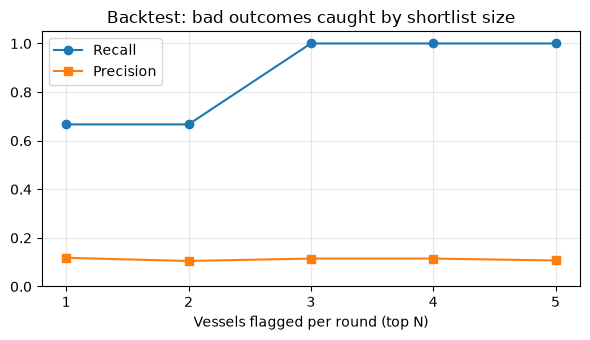

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(curve.index, curve["recall"], marker="o", label="Recall")
ax.plot(curve.index, curve["precision"], marker="s", label="Precision")
ax.set_xlabel("Vessels flagged per round (top N)")
ax.set_ylim(0, 1.05)
ax.set_xticks(curve.index)
ax.set_title("Backtest: bad outcomes caught by shortlist size")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

## Top of the ranking in each round

In [5]:
for rd in result["rounds"]:
    print(f"Round {rd['round']} ({rd['date_range'][0]} to {rd['date_range'][1]})")
    top = pd.DataFrame(rd["ranking"]).head(5)
    display(top[["rank", "vessel_id", "score", "outcome", "top_driver"]].set_index("rank"))

Round 2 (2024-06-30 to 2024-08-09)


,vessel_id,score,outcome,top_driver
rank,,,,
1,V001,12.0,Deficiencies Found,Last inspection INS0001 (2024-02-15): Deficien...
1,V002,12.0,Deficiencies Found,Last inspection INS0005 (2024-01-20): Deficien...
1,V003,12.0,Deficiencies Found,Last inspection INS0009 (2024-01-19): Deficien...
1,V005,12.0,No Major Findings,Last inspection INS0017 (2024-02-25): Deficien...
1,V006,12.0,No Major Findings,Last inspection INS0021 (2024-02-25): Deficien...


Round 3 (2024-12-13 to 2025-01-21)


,vessel_id,score,outcome,top_driver
rank,,,,
1,V001,26.4,Major Deficiencies,Last inspection INS0002 (2024-07-29): Deficien...
2,V004,24.5,Deficiencies Found,Last inspection INS0014 (2024-07-08): Deficien...
3,V002,22.6,Deficiencies Found,Last inspection INS0006 (2024-07-23): Deficien...
3,V011,22.6,No Major Findings,Last inspection INS0042 (2024-06-30): Deficien...
3,V012,22.6,Deficiencies Found,Last inspection INS0046 (2024-06-30): Deficien...


Round 4 (2025-05-26 to 2025-07-05)


,vessel_id,score,outcome,top_driver
rank,,,,
1,V001,50.0,Detained,Last inspection INS0003 (2025-01-11): Major De...
2,V018,23.0,No Major Findings,Last inspection INS0071 (2024-12-13): Deficien...
3,V004,21.5,Detained,Last inspection INS0015 (2025-01-01): Deficien...
3,V010,21.5,Deficiencies Found,Last inspection INS0039 (2025-01-08): Deficien...
5,V005,20.1,No Major Findings,Last inspection INS0019 (2024-12-13): Deficien...


## Reading the result

- V001's Major Deficiencies (round 3) and detention (round 4) both ranked #1.
- V004's detention ranked #3, tied with V010, behind V001 and V018. Before the detention, V004's record (2, 4 and 5 deficiencies, all closed, no major findings) looks the same as V018's and V010's on these features; its navigation focus only becomes visible in the open items and repeats raised at the detention itself.
- A shortlist of 2 per round catches 2 of 3 bad outcomes; a shortlist of 3 catches all 3.
- The solution proposal's quick backtest (a simpler inspection-only score) ranked the outcomes #1, #1 and #2. The full rule score was not retuned to reproduce that, because tuning to the only 3 test cases would make the backtest meaningless.

In [6]:
for caveat in result["caveats"]:
    print("-", caveat)

out = Path("backtest_results.json")
out.write_text(json.dumps(result, indent=2))
print(f"\nSaved {out.resolve().name}")

- Only 3 bad outcomes (V001 Major Deficiencies and Detention, V004 Detention) to test against: encouraging, not proof.
- The weights and thresholds were set after seeing this data, so the result is at risk of overfitting.
- Only inspection and deficiency history is backtested; maintenance, crew, audit and failure records are dated after the inspections.
- Round 1 is skipped because no vessel has any history before its first inspection.
- Vessels with equal scores share a rank and are all flagged at the cut-off, so a round with many ties (round 2, where every vessel has one prior inspection) raises the flag count.

Saved backtest_results.json
